## Results

Tables, figures and statistical tests for RQ1 and RQ2, built from the outputs of notebook 05.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scikit_posthocs as sp
import seaborn as sns
from scipy.stats import friedmanchisquare, t
from sklearn.metrics import roc_auc_score

PROCESSED = Path("../data/processed")
TABLES = Path("../results/tables")
FIGURES = Path("../results/figures")

GROUPS = ["toddler", "child", "adolescent", "adult"]
QUESTIONS = [f"A{i}" for i in range(1, 11)]
CUTOFF = {"toddler": 3, "child": 6, "adolescent": 6, "adult": 6}
MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "EBM", "TabPFN"]
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "brier"]

COLUMN, PAGE = 3.5, 7.16  # width of one column and of a full page in the IEEE format (inches)
sns.set_theme(style="whitegrid", font="serif", rc={
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "figure.titlesize": 9, "savefig.dpi": 300, "savefig.bbox": "tight",
})
SHORT = {"Logistic Regression": "LR", "Random Forest": "RF", "XGBoost": "XGB",
         "LightGBM": "LGBM", "EBM": "EBM", "TabPFN": "TabPFN"}

# the results that notebook 05 saved
cv = pd.read_csv(TABLES / "cv_folds.csv")
cross = pd.read_csv(TABLES / "cross_source.csv")

### 1. Main results (mean ± standard deviation over 15 test folds)

Lower is better for the Brier score; higher is better for everything else.

In [2]:
grouped = cv.groupby(["group", "model"])[METRICS]
# write each cell as "mean ± std"
table = grouped.mean().round(3).astype(str) + " ± " + grouped.std().round(3).astype(str)
table = table.reindex(pd.MultiIndex.from_product([GROUPS, MODEL_NAMES], names=["group", "model"]))
table.to_csv(TABLES / "main_results.csv")
table

accuracy      precision         recall  \
group      model                                                              
toddler    Logistic Regression  0.999 ± 0.002      1.0 ± 0.0  0.999 ± 0.003   
           Random Forest        0.962 ± 0.015  0.969 ± 0.017   0.978 ± 0.01   
           XGBoost              0.986 ± 0.009  0.993 ± 0.006  0.987 ± 0.009   
           LightGBM             0.977 ± 0.015  0.987 ± 0.012   0.98 ± 0.013   
           EBM                      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           TabPFN                   1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
child      Logistic Regression  0.999 ± 0.005  0.998 ± 0.009      1.0 ± 0.0   
           Random Forest        0.938 ± 0.031  0.921 ± 0.051  0.955 ± 0.041   
           XGBoost              0.949 ± 0.034  0.932 ± 0.059  0.967 ± 0.038   
           LightGBM             0.949 ± 0.046  0.943 ± 0.058  0.952 ± 0.046   
           EBM                      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           TabPFN               0.987 ± 0.014  0.983 ± 0.026   0.99 ± 0.017   
adolescent Logistic Regression   0.918 ± 0.05  0.905 ± 0.077  0.972 ± 0.051   
           Random Forest        0.892 ± 0.064  0.879 ± 0.073  0.956 ± 0.062   
           XGBoost              0.878 ± 0.051   0.87 ± 0.053  0.939 ± 0.074   
           LightGBM             0.888 ± 0.047  0.884 ± 0.054  0.939 ± 0.067   
           EBM                  0.937 ± 0.054   0.936 ± 0.07  0.967 ± 0.053   
           TabPFN               0.931 ± 0.048  0.923 ± 0.075  0.972 ± 0.041   
adult      Logistic Regression      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           Random Forest        0.972 ± 0.021  0.956 ± 0.047  0.941 ± 0.048   
           XGBoost              0.981 ± 0.011  0.956 ± 0.037  0.977 ± 0.023   
           LightGBM             0.968 ± 0.016  0.951 ± 0.033   0.93 ± 0.048   
           EBM                      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           TabPFN                   1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   

                                           f1        roc_auc          brier  
group      model                                                             
toddler    Logistic Regression  0.999 ± 0.002      1.0 ± 0.0  0.008 ± 0.007  
           Random Forest         0.973 ± 0.01  0.995 ± 0.003  0.035 ± 0.004  
           XGBoost               0.99 ± 0.006  0.999 ± 0.001  0.013 ± 0.005  
           LightGBM             0.984 ± 0.011  0.998 ± 0.002  0.018 ± 0.007  
           EBM                      1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
           TabPFN                   1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
child      Logistic Regression  0.999 ± 0.005      1.0 ± 0.0  0.028 ± 0.035  
           Random Forest         0.937 ± 0.03  0.988 ± 0.012  0.075 ± 0.011  
           XGBoost              0.948 ± 0.033  0.992 ± 0.012  0.037 ± 0.023  
           LightGBM             0.947 ± 0.046   0.99 ± 0.014  0.043 ± 0.036  
           EBM                      1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
           TabPFN               0.986 ± 0.015      1.0 ± 0.0  0.011 ± 0.005  
adolescent Logistic Regression   0.934 ± 0.04  0.988 ± 0.017  0.073 ± 0.046  
           Random Forest        0.913 ± 0.051   0.977 ± 0.02  0.085 ± 0.017  
           XGBoost              0.901 ± 0.044  0.965 ± 0.022  0.081 ± 0.027  
           LightGBM             0.908 ± 0.041  0.964 ± 0.025  0.089 ± 0.041  
           EBM                  0.949 ± 0.044  0.986 ± 0.016  0.051 ± 0.045  
           TabPFN               0.945 ± 0.037   0.99 ± 0.013   0.047 ± 0.02  
adult      Logistic Regression      1.0 ± 0.0      1.0 ± 0.0  0.004 ± 0.004  
           Random Forest        0.947 ± 0.039  0.996 ± 0.005   0.034 ± 0.01  
           XGBoost              0.966 ± 0.019  0.998 ± 0.002  0.015 ± 0.005  
           LightGBM              0.94 ± 0.031  0.997 ± 0.003  0.023 ± 0.009  
           EBM                      1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
           TabPFN               

### 2. Baseline: the scoring rule itself

Before reading the model scores, compare them with simply adding up the ten answers and applying the cut-off. No learning is involved.

In [3]:
rows = []
for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    # no model here. Only add up the answers and compare with the cut-off
    pred = (df[QUESTIONS].sum(axis=1) > CUTOFF[g]).astype(int)
    rows.append({"group": g, "records": len(df), "accuracy": (pred == df["asd"]).mean(),
                 "errors": int((pred != df["asd"]).sum())})
pd.DataFrame(rows)

,group,records,accuracy,errors
0,toddler,973,1.0,0
1,child,280,1.0,0
2,adolescent,101,1.0,0
3,adult,691,1.0,0


The rule is right 100 % of the time, because it *is* the label. Every model is therefore being measured on how closely it recovers a known formula from a few hundred examples. That is still a fair way to **compare** the models, but it is not evidence that any of them can detect autism.

### 2b. Sanity checks

Two controls to show that the perfect scores come from the data and not from the pipeline. First, the labels are shuffled: if anything leaked from the test folds, the score would stay high; if not, it falls to chance. Second, a plain logistic regression on the ten answers only, trained on the **raw downloaded files** with no cleaning at all, with a fresh hold-out split made before anything else touches the data.

In [4]:
import io
import re

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = QUESTIONS + ["age", "male", "jaundice", "family_asd"]
RAW = Path("../data/raw")


def read_arff(path):
    text = Path(path).read_text(encoding="latin-1")
    header, body = re.split("@data", text, flags=re.IGNORECASE)
    cols = [line.split()[1] for line in header.splitlines() if line.lower().startswith("@attribute")]
    return pd.read_csv(io.StringIO(body), header=None, names=cols, quotechar="'", na_values="?", skipinitialspace=True)


# (file, answer columns, label column)
raw = {
    "toddler": (pd.read_csv(RAW / "toddler/Toddler Autism dataset July 2018.csv"), QUESTIONS, "Class/ASD Traits "),
    "child": (read_arff(RAW / "child/Autism-Child-Data.arff"), [f"A{i}_Score" for i in range(1, 11)], "Class/ASD"),
    "adolescent": (read_arff(RAW / "adolescent/Autism-Adolescent-Data.arff"), [f"A{i}_Score" for i in range(1, 11)], "Class/ASD"),
    "adult": (read_arff(RAW / "adult/Autism-Adult-Data.arff"), [f"A{i}_Score" for i in range(1, 11)], "Class/ASD"),
}

rows = []
# stratified means every fold has the same share of positive cases
folds = StratifiedKFold(5, shuffle=True, random_state=0)
# for shuffling the labels
rng = np.random.RandomState(0)
for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    real = cross_val_score(lr, df[FEATURES], df["asd"], cv=folds, scoring="roc_auc").mean()
    # same model, but the labels are mixed up. The score should drop to about 0.5 (guessing)
    shuffled = cross_val_score(lr, df[FEATURES], rng.permutation(df["asd"]), cv=folds, scoring="roc_auc").mean()

    # now the raw file, with no cleaning at all
    rdf, qcols, ycol = raw[g]
    y = rdf[ycol].astype(str).str.strip().str.lower().eq("yes").astype(int).values
    # we use only the ten answers, not the total score column
    X = rdf[qcols].astype(int).values
    idx = np.random.RandomState(7).permutation(len(rdf))
    # mix the rows. The first 20% is the test set, the rest is for training
    test, train = idx[:len(rdf) // 5], idx[len(rdf) // 5:]
    # no scaling and no SMOTE (making extra rows for the smaller class) here, to keep this check simple
    prob = LogisticRegression(max_iter=5000).fit(X[train], y[train]).predict_proba(X[test])[:, 1]
    rows.append({"group": g, "LR AUC, real labels": real, "LR AUC, shuffled labels": shuffled,
                 "raw hold-out AUC": roc_auc_score(y[test], prob),
                 "raw hold-out errors": int(((prob >= 0.5) != y[test]).sum()), "raw hold-out size": len(test)})

sanity = pd.DataFrame(rows).set_index("group")
sanity.to_csv(TABLES / "sanity_checks.csv")
sanity.round(3)

,"LR AUC, real labels","LR AUC, shuffled labels",raw hold-out AUC,raw hold-out errors,raw hold-out size
group,,,,,
toddler,1.000,0.523,1.0,0,210
child,1.000,0.502,1.0,0,58
adolescent,0.985,0.472,1.0,0,20
adult,1.000,0.508,1.0,0,140


### 3. Spread across folds

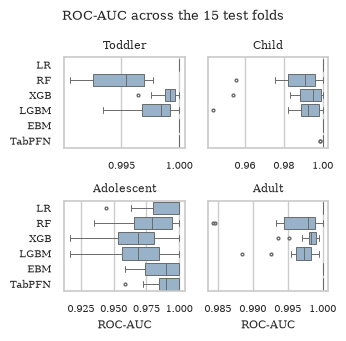

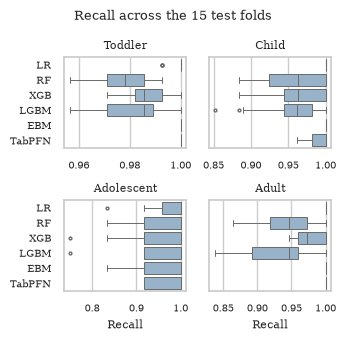

In [5]:
# short model names fit better in the plot
plot = cv.assign(model=cv.model.map(SHORT))

for metric, label in [("roc_auc", "ROC-AUC"), ("recall", "Recall")]:
    fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 3.4), sharey=True)
    for i, (ax, g) in enumerate(zip(axes.flat, GROUPS)):
        sns.boxplot(plot[plot.group == g], x=metric, y="model", order=SHORT.values(),
                    color="#8fb3d1", linewidth=0.7, fliersize=2, ax=ax)
        ax.set_title(g.capitalize())
        ax.set_xlabel(label if i >= 2 else "")
        ax.set_ylabel("")
    fig.suptitle(f"{label} across the 15 test folds")
    fig.tight_layout()
    fig.savefig(FIGURES / f"fig_cv_{metric}.png")

### 4. Are the differences real?

**Friedman test** (from the proposal): within each age group, are the six models' fold scores different overall? The 15 folds act as the blocks.

One caution: folds from repeated cross-validation share training data, so they are not fully independent and p-values come out a little too small. For the two models this study focuses on, EBM and TabPFN, a **corrected resampled t-test** (Nadeau & Bengio, 2003) is also run against every other model. It inflates the variance to account for this overlap.

In [6]:
rows = []
for g in GROUPS:
    for metric in ["roc_auc", "f1"]:
        # one row for each fold, one column for each model
        wide = cv[cv.group == g].pivot(index="fold", columns="model", values=metric)[MODEL_NAMES]
        # Friedman compares ranks, so the scores do not need a normal distribution (ANOVA needs that)
        stat, p = friedmanchisquare(*[wide[m] for m in MODEL_NAMES])
        rows.append({"group": g, "metric": metric, "chi2": round(stat, 2), "p": p})
friedman = pd.DataFrame(rows)
friedman

,group,metric,chi2,p
0,toddler,roc_auc,69.51,1.293739e-13
1,toddler,f1,69.29,1.436624e-13
2,child,roc_auc,53.90,2.200630e-10
3,child,f1,55.72,9.291889e-11
4,adolescent,roc_auc,28.87,2.453743e-05
5,adolescent,f1,23.65,2.535582e-04
6,adult,roc_auc,65.25,9.940676e-13
7,adult,f1,66.16,6.449715e-13


Nemenyi post-hoc test (p-values) for ROC-AUC, to see which pairs differ:

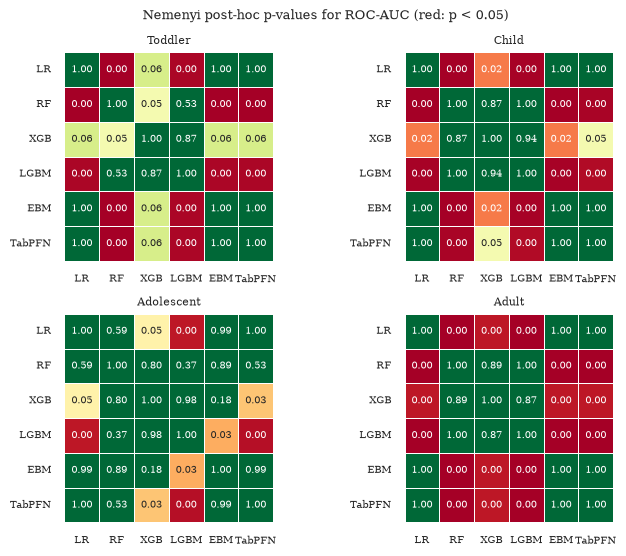

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(PAGE, 5.6))
for ax, g in zip(axes.flat, GROUPS):
    wide = cv[cv.group == g].pivot(index="fold", columns="model", values="roc_auc")[MODEL_NAMES]
    pvals = sp.posthoc_nemenyi_friedman(wide).rename(index=SHORT, columns=SHORT)
    # all p-values above 0.1 get the same colour
    sns.heatmap(pvals, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="RdYlGn",
                vmin=0, vmax=0.1, cbar=False, square=True, linewidths=0.4, ax=ax)
    ax.set_title(g.capitalize())
    ax.tick_params(rotation=0)
fig.suptitle("Nemenyi post-hoc p-values for ROC-AUC (red: p < 0.05)")
fig.tight_layout()
fig.savefig(FIGURES / "fig_nemenyi_roc_auc.png")

In [8]:
# t-test for cross-validation scores. test_frac is the size of a test fold (20%)
def corrected_ttest(a, b, test_frac=0.2):
    d = a - b
    # the second part makes the variance bigger, because the folds share training rows
    var = d.var(ddof=1) * (1 / len(d) + test_frac / (1 - test_frac))
    # both models have the same score in every fold
    if var == 0:
        return 0.0, 1.0
    stat = d.mean() / var ** 0.5
    # p-value for a difference in either direction
    return stat, 2 * t.sf(abs(stat), len(d) - 1)


rows = []
for g in GROUPS:
    wide = cv[cv.group == g].pivot(index="fold", columns="model", values="roc_auc")
    for focus in ["EBM", "TabPFN"]:
        for other in MODEL_NAMES:
            if other == focus:
                continue
            stat, p = corrected_ttest(wide[focus], wide[other])
            rows.append({"group": g, "model": focus, "vs": other,
                         "AUC difference": wide[focus].mean() - wide[other].mean(), "p": p})

ttests = pd.DataFrame(rows)
ttests["significant"] = ttests["p"] < 0.05
ttests.round(4)

,group,model,vs,AUC difference,p,significant
0,toddler,EBM,Logistic Regression,0.0000,1.0000,False
1,toddler,EBM,Random Forest,0.0053,0.0023,True
2,toddler,EBM,XGBoost,0.0010,0.0899,False
3,toddler,EBM,LightGBM,0.0022,0.0847,False
4,toddler,EBM,TabPFN,0.0000,1.0000,False
5,toddler,TabPFN,Logistic Regression,0.0000,1.0000,False
6,toddler,TabPFN,Random Forest,0.0053,0.0023,True
7,toddler,TabPFN,XGBoost,0.0010,0.0899,False
8,toddler,TabPFN,LightGBM,0.0022,0.0847,False
9,toddler,TabPFN,EBM,0.0000,1.0000,False


### 5. Missed cases

In screening, a **false negative** (a child with ASD traits sent home as "no concern") is the costliest mistake. Counts are summed over all 15 folds, so each record is counted three times (once per repeat).

In [9]:
# add up the right and wrong predictions of all 15 folds
errors = cv.groupby(["group", "model"])[["tp", "fn", "fp", "tn"]].sum()
errors = errors.reindex(pd.MultiIndex.from_product([GROUPS, MODEL_NAMES]))
errors["missed %"] = (100 * errors["fn"] / (errors["fn"] + errors["tp"])).round(2)
errors

tp  fn  fp    tn  missed %
toddler    Logistic Regression  2067   3   0   849      0.14
           Random Forest        2025  45  66   783      2.17
           XGBoost              2043  27  15   834      1.30
           LightGBM             2029  41  26   823      1.98
           EBM                  2070   0   0   849      0.00
           TabPFN               2070   0   0   849      0.00
child      Logistic Regression   399   0   1   440      0.00
           Random Forest         381  18  34   407      4.51
           XGBoost               386  13  30   411      3.26
           LightGBM              380  19  24   417      4.76
           EBM                   399   0   0   441      0.00
           TabPFN                395   4   7   434      1.00
adolescent Logistic Regression   175   5  20   103      2.78
           Random Forest         172   8  25    98      4.44
           XGBoost               169  11  26    97      6.11
           LightGBM              169  11  23   100      6.11
           EBM                   174   6  13   110      3.33
           TabPFN                175   5  16   107      2.78
adult      Logistic Regression   555   0   0  1518      0.00
           Random Forest         522  33  25  1493      5.95
           XGBoost               542  13  26  1492      2.34
           LightGBM              516  39  27  1491      7.03
           EBM                   555   0   0  1518      0.00
           TabPFN                555   0   0  1518      0.00

### 6. Cross-source results (RQ2)

The `in-source` column is the cross-validated ROC-AUC of the same model on its own training source, for comparison.

In [10]:
# the AUC of the same model on its own data, to compare
in_source = cv.groupby(["group", "model"])["roc_auc"].mean()
cross["in-source AUC"] = [in_source.get((tr, m)) for tr, m in zip(cross["train"], cross["model"])]
cross[["train", "test", "model", "roc_auc", "in-source AUC", "recall", "precision", "brier"]].round(3)

,train,test,model,roc_auc,in-source AUC,recall,precision,brier
0,toddler,toddler_saudi,Logistic Regression,1.000,1.000,1.000,1.000,0.011
1,toddler,toddler_saudi,Random Forest,0.998,0.995,0.990,0.981,0.026
2,toddler,toddler_saudi,XGBoost,1.000,0.999,0.997,1.000,0.005
3,toddler,toddler_saudi,LightGBM,1.000,0.998,0.997,0.993,0.005
4,toddler,toddler_saudi,EBM,1.000,1.000,1.000,1.000,0.000
5,toddler,toddler_saudi,TabPFN,1.000,1.000,1.000,1.000,0.000
6,toddler_saudi,toddler,Logistic Regression,1.000,NaN,1.000,1.000,0.001
7,toddler_saudi,toddler,Random Forest,0.986,NaN,0.942,0.972,0.055
8,toddler_saudi,toddler,XGBoost,0.994,NaN,0.942,0.992,0.037
9,toddler_saudi,toddler,LightGBM,0.992,NaN,0.920,0.986,0.055


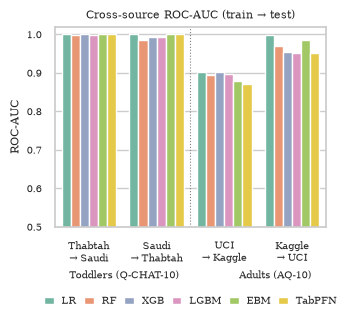

In [11]:
PAIR_NAMES = {"toddler": "Thabtah", "toddler_saudi": "Saudi", "adult": "UCI", "adult_kaggle": "Kaggle"}
plot = cross.assign(model=cross.model.map(SHORT),
                    pair=[f"{PAIR_NAMES[a]}\n→ {PAIR_NAMES[b]}" for a, b in zip(cross.train, cross.test)])

fig, ax = plt.subplots(figsize=(COLUMN, 2.6))
sns.barplot(plot, x="pair", y="roc_auc", hue="model", hue_order=SHORT.values(), palette="Set2", ax=ax)
ax.set_ylim(0.5, 1.02)
ax.set_title("Cross-source ROC-AUC (train → test)")
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("Toddlers (Q-CHAT-10)                    Adults (AQ-10)", fontsize=7)
# dotted line between the toddler bars and the adult bars
ax.axvline(1.5, color="grey", lw=0.8, ls=":")
sns.move_legend(ax, "upper center", bbox_to_anchor=(0.5, -0.3), ncol=6, title=None, frameon=False,
                columnspacing=0.8, handlelength=1)
fig.savefig(FIGURES / "fig_cross_source.png")

### 7. Bias check

Using the out-of-fold predictions saved in notebook 05, recall and false-positive rate are compared across gender and ethnicity for the model chosen for each age group. Ethnic groups with fewer than 20 records are merged into "Other/Unknown", because rates on a handful of people mean nothing.

In [12]:
preds = pd.read_csv(TABLES / "cv_predictions.csv")
chosen = pd.read_csv("../app/data/chosen_models.csv", index_col="group")["model"]


# every person is in the predictions 3 times, once in each repeat
def rates(df):
    pos, neg = df[df.asd == 1], df[df.asd == 0]
    return pd.Series({"records": len(df) // 3,
                      "recall": (pos.prob >= 0.5).mean() if len(pos) else None,
                      "false positive rate": (neg.prob >= 0.5).mean() if len(neg) else None})


rows = []
for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    # add the personal details to the predictions
    p = preds[(preds.group == g) & (preds.model == chosen[g])].merge(df, left_on="row", right_index=True)
    # small ethnic groups go into one group, they are too small to measure alone
    common = p.ethnicity.value_counts()
    # 60 rows = 20 people, because every person is there 3 times
    p["ethnicity"] = (p.ethnicity.where(p.ethnicity.map(common) >= 60, "Other/Unknown")  # 20 people x 3 repeats
                                 .replace({"Other": "Other/Unknown", "Unknown": "Other/Unknown"}))
    p["gender"] = p.male.map({1: "male", 0: "female"})
    for col in ["gender", "ethnicity"]:
        for value, part in p.groupby(col):
            rows.append({"group": g, "model": chosen[g], "attribute": col, "value": value, **rates(part)})

bias = pd.DataFrame(rows)
bias.round(3)

,group,model,attribute,value,records,recall,false positive rate
0,toddler,EBM,gender,female,291.0,1.000,0.000
1,toddler,EBM,gender,male,682.0,1.000,0.000
2,toddler,EBM,ethnicity,Asian,272.0,1.000,0.000
3,toddler,EBM,ethnicity,Black,48.0,1.000,0.000
4,toddler,EBM,ethnicity,Hispanic,37.0,1.000,0.000
5,toddler,EBM,ethnicity,Latino,26.0,1.000,0.000
6,toddler,EBM,ethnicity,Middle Eastern,167.0,1.000,0.000
7,toddler,EBM,ethnicity,Other/Unknown,52.0,1.000,0.000
8,toddler,EBM,ethnicity,South Asian,60.0,1.000,0.000
9,toddler,EBM,ethnicity,White European,311.0,1.000,0.000


### 8. Answers

**RQ1: How do EBM and TabPFN compare with the established models when leakage is controlled?**

* In the toddler, child and adult data, EBM and TabPFN are **perfect or almost perfect** (ROC-AUC 1.000, recall 1.000, Brier score ≈ 0). So is plain **Logistic Regression**. All three can represent "add up the answers and compare with a cut-off" directly.
* The tree ensembles (Random Forest, XGBoost, LightGBM) are slightly behind (ROC-AUC 0.988–0.999) and **miss 1–7 % of positive cases**. Their one-feature-at-a-time splits can only approximate a sum. The Friedman test confirms that the six models differ in every group.
* After correcting for overlapping folds, EBM and TabPFN are significantly better than Random Forest only for toddlers. None of the other differences reach p < 0.05, and **neither model is ever better than Logistic Regression**.
* **Adolescents** (101 records) are the hardest group for every model (ROC-AUC 0.964–0.990). TabPFN, Logistic Regression and EBM lead, but the differences are not significant.
* **Conclusion:** EBM and TabPFN match the best model in every group, which makes EBM attractive because it is also fully readable. However, they do not beat a simple logistic regression on this data, because the label is a linear rule.

**RQ2: Do the models work on data from a different source?**

* **Toddlers transfer perfectly** in both directions (Thabtah ↔ Saudi). Both datasets use the same Q-CHAT-10 scoring rule to make the label, so a model that learned the rule on one works on the other.
* **Adults do not.** Trained on UCI and tested on Kaggle, ROC-AUC drops from about 1.00 to **0.87–0.90** and precision falls to about 0.52, because the Kaggle labels follow the scoring rule only 80 % of the time. EBM (0.879) and TabPFN (0.871) are the *lowest*: the models that copy the source rule most exactly transfer worst when the rule changes.
* In the other direction (Kaggle → UCI), Logistic Regression recovers best (0.998), then EBM (0.984). TabPFN keeps a good ROC-AUC (0.952) but finds only 41 % of positive cases at the 0.5 threshold.
* **Conclusion:** cross-source performance depends on *how the labels were made*, not on the model. In-source accuracy close to 100 % says little about performance elsewhere.

**Bias check.** For toddlers, children and adults the chosen model makes no errors in any gender or ethnic group, so no bias can be measured. The point is that the label rule is applied the same way to everyone, not that the models are fair. For adolescents, the false-positive rate is higher for girls (0.24 vs 0.10), but this rests on about 20 negative cases per gender and should be treated as a pointer for future work, not a finding.